# Batched spin-weighted spheroidal harmonics with `hblteuk.jax`

Demonstrates the Phase 1 JAX backend: spheroidal eigenvalues and
spherical-expansion coefficients for **thousands of modes in a single batched
call**, replacing the per-mode ARPACK loop.

Requirements: conda env `hblteuk-env` (or any env with
`pip install -e ".[dev,jax]" matplotlib`). Design/validation notes:
`dev/GPU_PLAN.md`, `dev/PHASE1.md`; numerical checks are visualized in
`examples/jax_swsh_validation.ipynb`.

On this machine JAX runs on CPU; the identical code targets A100s on the
cluster (`jax.devices()` below tells you what you're on).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax

from hblteuk.jax import spheroidal_eigs_batched, sphericalY_basis_matrix
from hblteuk.swsh import SpinWeightedSpheroidalHarmonic

# Okabe-Ito colorblind-safe categorical palette, fixed assignment order
C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

print("jax", jax.__version__, "| devices:", jax.devices())
print("x64 enabled:", jax.config.jax_enable_x64)

jax 0.10.2 | devices: [CpuDevice(id=0)]
x64 enabled: True


## 1. Build a mode batch

A realistic $s=-2$ mode table: every $(\ell, m)$ with $2 \le \ell \le
\ell_{\max}$, and spheroidicity $\gamma = a\,\omega_{m00}$ from a circular
orbit ($a = 0.9$, $p = 10$). One flat batch, one call.

In [2]:
from hblteuk.geo import MiniGeo

orbit = MiniGeo(0.9, 10.0, 0.0, 1.0)
lmax = 40

modes = [(l, m) for l in range(2, lmax + 1) for m in range(-l, l + 1)]
l_arr = np.array([lm[0] for lm in modes])
m_arr = np.array([lm[1] for lm in modes])
g_arr = np.array([orbit.a * orbit.mode_frequency(m, 0, 0) for m in m_arr])

print(f"batch size B = {len(modes)} modes, spheroidicity range "
      f"[{g_arr.min():.2f}, {g_arr.max():.2f}]")

batch size B = 1677 modes, spheroidicity range [-1.11, 1.11]


In [3]:
eigenvalues, coeffs, lmin = spheroidal_eigs_batched(-2, l_arr, m_arr, g_arr)
eigenvalues.block_until_ready()
print("eigenvalues:", eigenvalues.shape, "| coeffs:", coeffs.shape)

eigenvalues: (1677,) | coeffs: (1677, 60)


## 2. Eigenvalue landscape

Spheroidal eigenvalue $\lambda_{\ell m}(\gamma)$ vs $\ell$, colored by $m$
(diverging colormap, neutral at $m=0$). The $\gamma \to 0$ limit is
$\ell(\ell+1) - s(s+1)$ (gray dashed reference).

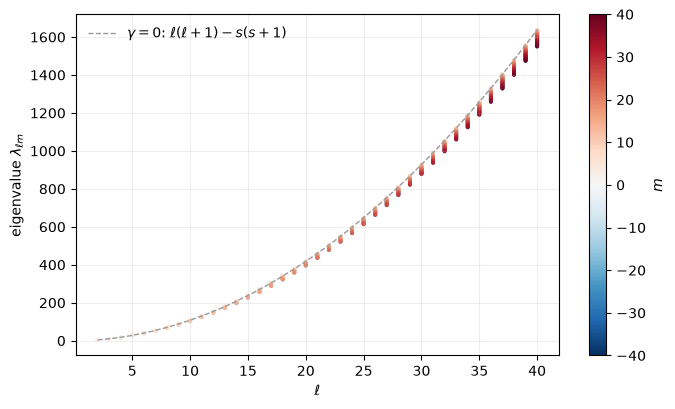

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sc = ax.scatter(l_arr, eigenvalues, c=m_arr, cmap="RdBu_r",
                vmin=-lmax, vmax=lmax, s=8, linewidths=0)
lref = np.arange(2, lmax + 1)
ax.plot(lref, lref * (lref + 1) - 2, ls="--", c="0.6", lw=1,
        label=r"$\gamma=0$: $\ell(\ell+1)-s(s+1)$")
ax.set_xlabel(r"$\ell$")
ax.set_ylabel(r"eigenvalue $\lambda_{\ell m}$")
ax.legend(frameon=False)
fig.colorbar(sc, label=r"$m$")
ax.grid(alpha=0.2)
plt.tight_layout()

## 3. Evaluate harmonics

Coefficients are spherical-harmonic expansion weights: $S_{\ell m}(\theta) =
\sum_j c_j\, Y_{s,\,\ell_{\min}+j,\,m}(\cos\theta)$. The
$Y$-basis matrix is built once on CPU; evaluation is a single matrix
product per mode family.

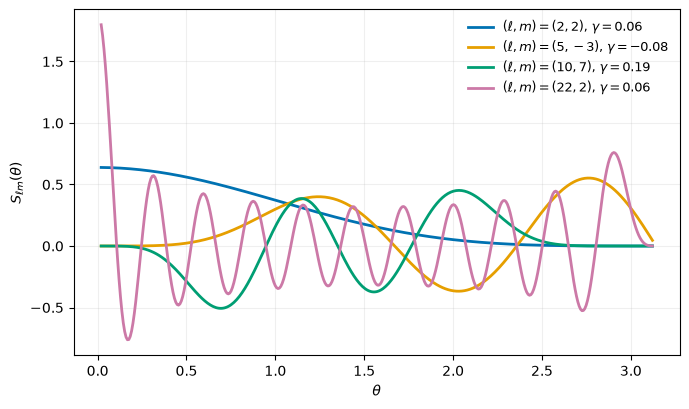

In [5]:
th = np.linspace(0.02, np.pi - 0.02, 400)
z = np.cos(th)

show = [(2, 2), (5, -3), (10, 7), (22, 2)]
fig, ax = plt.subplots(figsize=(7, 4.2))
for color, (l, m) in zip(C, show):
    b = modes.index((l, m))
    basis = sphericalY_basis_matrix(-2, m, int(lmin[b]), coeffs.shape[1], z)
    S = np.asarray(coeffs[b]) @ basis
    ax.plot(th, S, lw=2, color=color,
            label=rf"$(\ell, m) = ({l}, {m})$, $\gamma = {g_arr[b]:.2f}$")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$S_{\ell m}(\theta)$")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()

## 4. Performance: one batched call vs the per-mode loop

The CPU loop is timed on a subset and extrapolated (it is embarrassingly
linear in mode count). First batched call includes XLA compilation;
subsequent calls at the same batch shape reuse the compiled kernel.

In [6]:
import time

t0 = time.perf_counter()
lam2, _, _ = spheroidal_eigs_batched(-2, l_arr, m_arr, g_arr)
lam2.block_until_ready()
t_batch = time.perf_counter() - t0

nsub = 150
t0 = time.perf_counter()
for i in range(nsub):
    SpinWeightedSpheroidalHarmonic(-2, int(l_arr[i]), int(m_arr[i]), g_arr[i])
t_loop = (time.perf_counter() - t0) / nsub * len(modes)

print(f"batched (cached compile): {t_batch*1e3:8.1f} ms   for B = {len(modes)}")
print(f"CPU per-mode loop (extrapolated): {t_loop*1e3:8.0f} ms")
print(f"speedup on {jax.devices()[0].platform.upper()}: {t_loop/t_batch:.0f}x")

batched (cached compile):     28.9 ms   for B = 1677
CPU per-mode loop (extrapolated):     1749 ms
speedup on CPU: 61x


## Next

Phase 2 batches the radial Teukolsky solutions (`vmap` over modes,
`lax.scan` over the subdomain march) — these eigenvalues feed directly into
that solver. See `dev/GPU_PLAN.md` §2.1.